In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
data_path = Path("Iris.csv")
if not data_path.exists():
    data_path = Path("Assignment11") / "Iris (1).csv"

df = pd.read_csv(data_path)
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn information:")
df.info()
print("\nSummary statistics:")
display=(df.describe(include="all"))
print("\nSpecies counts (used only to understand the dataset):")
print(df["Species"].value_counts())

Dataset shape: (150, 6)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Summary statistics:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
count,150.000000,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,NaN,Iris-setosa
freq,NaN,NaN,NaN,NaN,NaN,50
mean,75.500000,5.843333,3.054000,3.758667,1.198667,NaN
std,43.445368,0.828066,0.433594,1.764420,0.763161,NaN
min,1.000000,4.300000,2.000000,1.000000,0.100000,NaN
25%,38.250000,5.100000,2.800000,1.600000,0.300000,NaN
50%,75.500000,5.800000,3.000000,4.350000,1.300000,NaN
75%,112.750000,6.400000,3.300000,5.100000,1.800000,NaN



Species counts (used only to understand the dataset):
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [4]:
feature_columns = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm",
]
X = df[feature_columns]

print(X.head())

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2


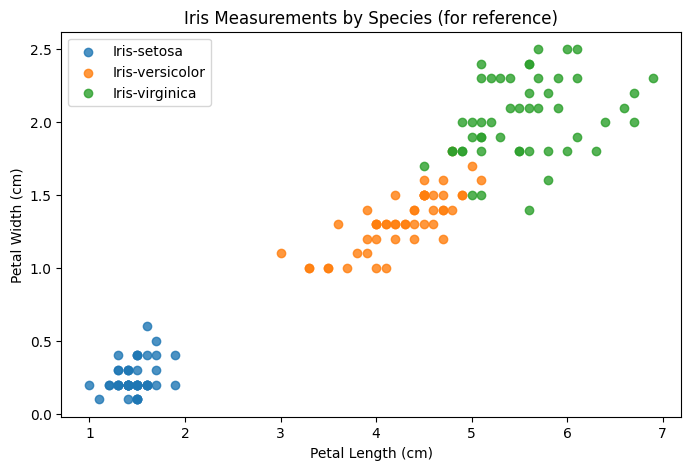

In [5]:
plt.figure(figsize=(8, 5))
for species in sorted(df["Species"].unique()):
    rows = df["Species"] == species
    plt.scatter(
        df.loc[rows, "PetalLengthCm"],
        df.loc[rows, "PetalWidthCm"],
        label=species,
        alpha=0.8,
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Measurements by Species (for reference)")
plt.legend()
plt.show()

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

K = 3
print("Number of clusters (K):", K)

Number of clusters (K): 3


In [7]:
def pam_k_medoids(data, n_clusters, random_state=42, max_iter=100):
    """Cluster rows with PAM and return labels, medoid indices, and cost."""
    data = np.asarray(data, dtype=float)
    n_samples = data.shape[0]
    if not 1 <= n_clusters < n_samples:
        raise ValueError("n_clusters must be between 1 and the number of samples - 1")

    distances = pairwise_distances(data, metric="euclidean")
    rng = np.random.default_rng(random_state)
    medoids = rng.choice(n_samples, size=n_clusters, replace=False)

    for _ in range(max_iter):
        current_cost = distances[:, medoids].min(axis=1).sum()
        best_cost = current_cost
        best_medoids = medoids.copy()
        non_medoids = np.setdiff1d(np.arange(n_samples), medoids)

        for medoid_position in range(n_clusters):
            for candidate in non_medoids:
                trial_medoids = medoids.copy()
                trial_medoids[medoid_position] = candidate
                trial_cost = distances[:, trial_medoids].min(axis=1).sum()
                if trial_cost < best_cost - 1e-12:
                    best_cost = trial_cost
                    best_medoids = trial_medoids

        if best_cost >= current_cost - 1e-12:
            break
        medoids = best_medoids

    labels = distances[:, medoids].argmin(axis=1)
    total_cost = distances[np.arange(n_samples), medoids[labels]].sum()
    return labels, medoids, total_cost

In [8]:
labels, medoid_indices, total_distance = pam_k_medoids(
    X_scaled,
    n_clusters=K,
    random_state=42,
)

print("Total distance to assigned medoids:", round(total_distance, 3))

Total distance to assigned medoids: 132.341


In [9]:
print(labels)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 2 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [10]:
df["Cluster"] = labels
print(df[["Id", "Species", "Cluster"]].head())

   Id      Species  Cluster
0   1  Iris-setosa        1
1   2  Iris-setosa        1
2   3  Iris-setosa        1
3   4  Iris-setosa        1
4   5  Iris-setosa        1


In [11]:
medoids = df.iloc[medoid_indices][["Id", *feature_columns, "Species"]].copy()
medoids.insert(0, "Cluster", np.arange(K))
display(medoids.reset_index(drop=True))

,Cluster,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,56,5.7,2.8,4.5,1.3,Iris-versicolor
1,1,8,5.0,3.4,1.5,0.2,Iris-setosa
2,2,113,6.8,3.0,5.5,2.1,Iris-virginica


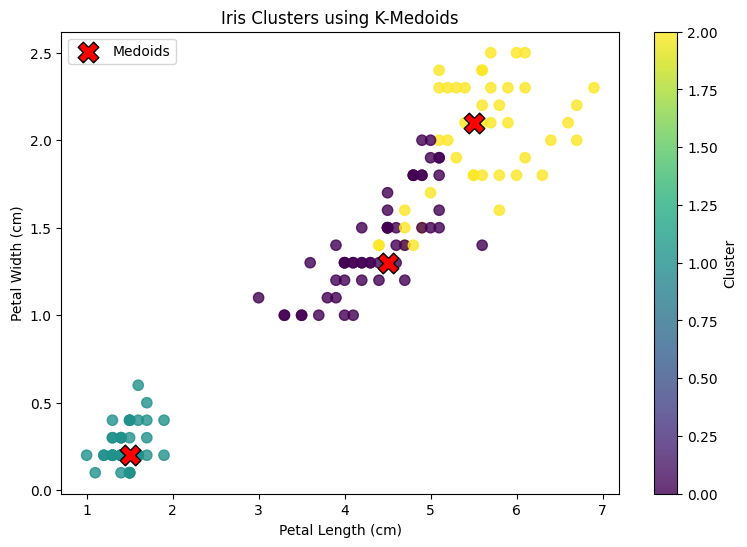

In [12]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["PetalLengthCm"],
    df["PetalWidthCm"],
    c=labels,
    cmap="viridis",
    s=55,
    alpha=0.8,
)
plt.scatter(
    df.iloc[medoid_indices]["PetalLengthCm"],
    df.iloc[medoid_indices]["PetalWidthCm"],
    c="red",
    marker="X",
    s=220,
    edgecolor="black",
    label="Medoids",
)
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Clusters using K-Medoids")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.show()

In [13]:
cluster_means = df.groupby("Cluster")[feature_columns].mean()
print("Average measurements by cluster:")
display(cluster_means)

print("Species counts by cluster (for interpretation only):")
display(pd.crosstab(df["Cluster"], df["Species"]))

print("Silhouette score:", round(silhouette_score(X_scaled, labels), 3))

Average measurements by cluster:


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.812727,2.700000,4.376364,1.412727
1,5.006000,3.418000,1.464000,0.244000
2,6.811111,3.082222,5.553333,1.997778


Species counts by cluster (for interpretation only):


Species,Iris-setosa,Iris-versicolor,Iris-virginica
Cluster,,,
0,0,41,14
1,50,0,0
2,0,9,36


Silhouette score: 0.456
